# State Unemployment Forecasting

- Data: 50 states and DC, 2014–2024.
- Goal: predict unemployment rates three reference months ahead.
- Midterm: API collection, data checks, and exploratory data analysis.

## 1. Check the environment

- Use the `data1030` kernel.
- Check Python and package versions.


In [1]:
import sys
import json
import urllib.request
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd

assert Path(sys.prefix).name == "data1030", "Please select the Python (data1030) kernel."
ROOT = Path.cwd()
assert (ROOT / "unemployment_linear_regression.ipynb").exists(), \
    "Please run this notebook from the directory containing unemployment_linear_regression.ipynb."

print("Environment:", Path(sys.prefix).name)
print("Python:", sys.version.split()[0])
print("numpy:", np.__version__, "pandas:", pd.__version__)

Environment: data1030
Python: 3.14.6
numpy: 2.4.6 pandas: 3.0.3


## 2. Collect BLS data

- Download seasonally adjusted monthly unemployment rates.
- Use six API requests; save and reuse the raw JSON files.
- Skip annual averages (`M13`).
- Check for missing months, duplicates, and invalid rates.
- Sources: [API format](https://www.bls.gov/developers/api_signature.htm), [API limits](https://www.bls.gov/developers/api_FAQs.htm), [definitions](https://www.bls.gov/help/def/la.htm), [state codes](https://download.bls.gov/pub/time.series/la/la.area).


In [2]:
API = "https://api.bls.gov/publicAPI/v1/timeseries/data/"
state_codes = "01 02 04 05 06 08 09 10 11 12 13 15 16 17 18 19 20 21 22 23 24 25 26 27 28 29 30 31 32 33 34 35 36 37 38 39 40 41 42 44 45 46 47 48 49 50 51 53 54 55 56".split()
series_to_state = {f"LASST{fips}0000000000003": fips for fips in state_codes}
assert len(series_to_state) == 51
assert "LASST440000000000003" in series_to_state
series_ids = list(series_to_state)
requests = [{"seriesid": series_ids[i:i+25], "startyear": str(start), "endyear": str(end)}
            for start, end in [(2014, 2023), (2024, 2024)]
            for i in range(0, len(series_ids), 25)]
print("POST", API)
print("Example payload:", json.dumps({"seriesid": ["LASST440000000000003"],
                                     "startyear": "2014", "endyear": "2023"}))

raw_dir = ROOT / "raw"
raw_dir.mkdir(exist_ok=True)
rows = []
for number, payload in enumerate(requests, 1):
    path = raw_dir / f"batch_{number:02d}.json"
    if path.exists():
        saved = json.loads(path.read_text())
        assert saved["request"] == payload, "Cached request parameters do not match. Please check the raw directory."
        response = saved["response"]
        print(f"Batch {number}/{len(requests)}: local API response")
    else:
        request = urllib.request.Request(API, data=json.dumps(payload).encode(),
                                         headers={"Content-Type": "application/json"}, method="POST")
        with urllib.request.urlopen(request, timeout=45) as connection:
            response = json.load(connection)
        assert response.get("status") == "REQUEST_SUCCEEDED", response.get("message")
        saved = {"retrieved_at_utc": datetime.now(timezone.utc).isoformat(),
                 "request": payload, "response": response}
        path.write_text(json.dumps(saved, ensure_ascii=False) + "\n")
        print(f"Batch {number}/{len(requests)}: collected via API")
    assert response.get("status") == "REQUEST_SUCCEEDED", response.get("message")
    returned = response["Results"]["series"]
    returned_ids = [item["seriesID"] for item in returned]
    assert set(returned_ids) == set(payload["seriesid"]) and len(returned_ids) == len(payload["seriesid"])
    for item in returned:
        for point in item["data"]:
            if point["period"] == "M13":
                continue
            assert point["period"] in {f"M{month:02d}" for month in range(1, 13)}
            rows.append({"state_code": series_to_state[item["seriesID"]],
                         "month": f'{point["year"]}-{point["period"][1:]}',
                         "unemployment_rate": float(point["value"].replace(",", ""))})
data = pd.DataFrame(rows).sort_values(["state_code", "month"]).reset_index(drop=True)
assert not data.duplicated(["state_code", "month"]).any()
assert data.groupby("state_code").size().eq(132).all() and len(data) == 51 * 132
assert data.month.between("2014-01", "2024-12").all()
assert data.unemployment_rate.between(0, 100).all() and np.isfinite(data.unemployment_rate).all()
data.to_csv(ROOT / "state_month_unemployment.csv", index=False)
print("Shape:", data.shape, "| range:", data.month.min(), "to", data.month.max())
display(data[data.state_code == "44"].head())


POST https://api.bls.gov/publicAPI/v1/timeseries/data/
Example payload: {"seriesid": ["LASST440000000000003"], "startyear": "2014", "endyear": "2023"}
Batch 1/6: local API response
Batch 2/6: local API response
Batch 3/6: local API response
Batch 4/6: local API response
Batch 5/6: local API response
Batch 6/6: local API response
Shape: (6732, 3) | range: 2014-01 to 2024-12


,state_code,month,unemployment_rate
5148,44,2014-01,8.9
5149,44,2014-02,8.7
5150,44,2014-03,8.5
5151,44,2014-04,8.2
5152,44,2014-05,8.0


## 3. Prepare three-month pairs for EDA

- One row = one state and one reference month.
- Pair the current rate with the actual rate three months later.
- Align monthly dates within each state before shifting values.
- Explore origins from January 2015 through September 2024.
- Rates are percentages: `4.5` means 4.5%.

In [3]:
calendar = pd.period_range(data.month.min(), data.month.max(), freq="M")
pieces = []
for state, group in data.groupby("state_code", sort=True):
    group = group.copy()
    group["month"] = pd.PeriodIndex(group.month, freq="M")
    history = group.set_index("month")[["unemployment_rate"]].reindex(calendar)
    history["target_unemployment_rate"] = history.unemployment_rate.shift(-3)
    history["target_month"] = (calendar + 3).astype(str)
    history["state_code"] = state
    history["month"] = calendar.astype(str)
    pieces.append(history.reset_index(drop=True))

table = pd.concat(pieces, ignore_index=True)
table = table[table.month >= "2015-01"].dropna(
    subset=["unemployment_rate", "target_unemployment_rate"]
).copy()
assert len(table) == 5967
assert not table.duplicated(["state_code", "month"]).any()
assert np.isfinite(table[["unemployment_rate", "target_unemployment_rate"]].to_numpy()).all()
table.to_csv(ROOT / "eda_pairs.csv", index=False)
print("Complete three-month pairs:", table.shape)
display(table[table.state_code == "44"].head())

Complete three-month pairs: (5967, 5)


,unemployment_rate,target_unemployment_rate,target_month,state_code,month
5160,6.5,6.3,2015-04,44,2015-01
5161,6.4,6.2,2015-05,44,2015-02
5162,6.4,6.0,2015-06,44,2015-03
5163,6.3,5.9,2015-07,44,2015-04
5164,6.2,5.8,2015-08,44,2015-05


## 4. Explore the data

- Figure 1: How do unemployment rates change over time and across states?
- Figure 2: How closely do current rates track rates three months later?
- Figure 3: How do future-rate distributions differ across calendar periods?
- Figure 4: How does unemployment-rate autocorrelation change with monthly lag?
- These figures describe the observed data; they do not measure forecast accuracy.

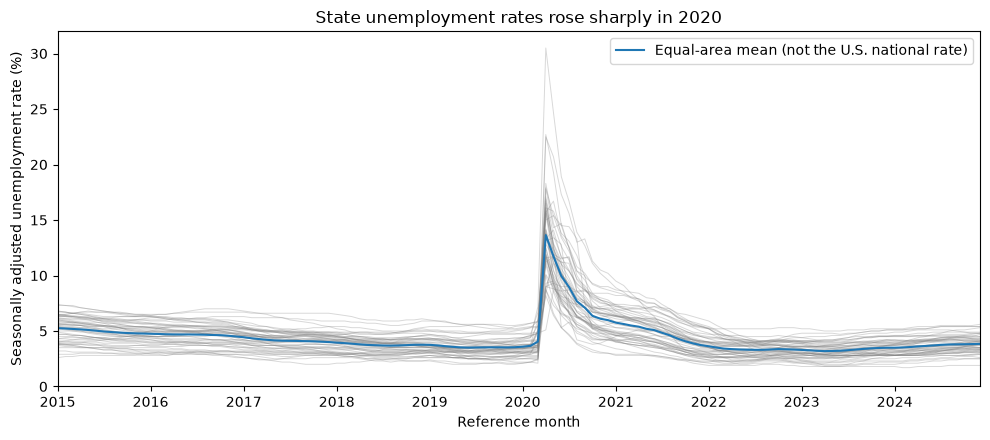

In [4]:
%matplotlib inline
import matplotlib.pyplot as plt

trend = data[data["month"] >= "2015-01"].pivot(
    index="month", columns="state_code", values="unemployment_rate"
)
plot_months = pd.to_datetime(trend.index)

plt.figure(figsize=(10, 4.5))
plt.plot(plot_months, trend, color="gray", alpha=0.3, linewidth=0.7)
plt.plot(plot_months, trend.mean(axis=1), color="tab:blue",
         label="Equal-area mean (not the U.S. national rate)")
plt.title("State unemployment rates rose sharply in 2020")
plt.xlabel("Reference month")
plt.ylabel("Seasonally adjusted unemployment rate (%)")
plt.xlim(plot_months.min(), plot_months.max())
plt.ylim(0, 32)
plt.legend()
plt.tight_layout()
plt.show()


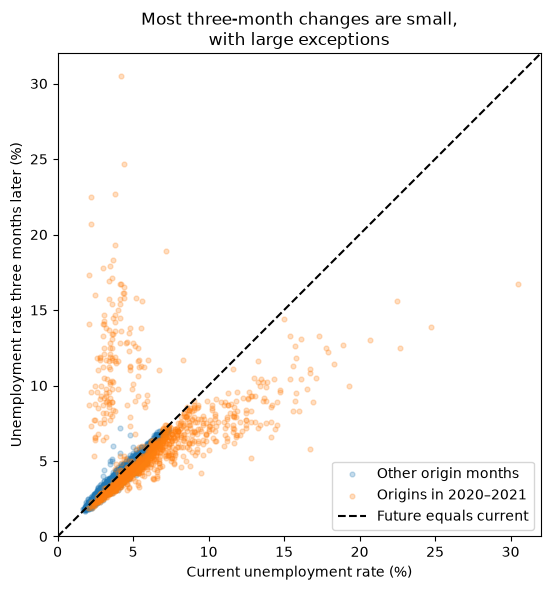

In [5]:
pandemic_months = table["month"].between("2020-01", "2021-12")

plt.figure(figsize=(6.5, 6))
plt.scatter(table.loc[~pandemic_months, "unemployment_rate"],
            table.loc[~pandemic_months, "target_unemployment_rate"],
            s=12, alpha=0.25, color="tab:blue", label="Other origin months")
plt.scatter(table.loc[pandemic_months, "unemployment_rate"],
            table.loc[pandemic_months, "target_unemployment_rate"],
            s=12, alpha=0.25, color="tab:orange", label="Origins in 2020–2021")
plt.plot([0, 32], [0, 32], "k--", label="Future equals current")
plt.title("Most three-month changes are small,\nwith large exceptions")
plt.xlabel("Current unemployment rate (%)")
plt.ylabel("Unemployment rate three months later (%)")
plt.axis("scaled")
plt.xlim(0, 32)
plt.ylim(0, 32)
plt.legend()
plt.tight_layout()
plt.show()


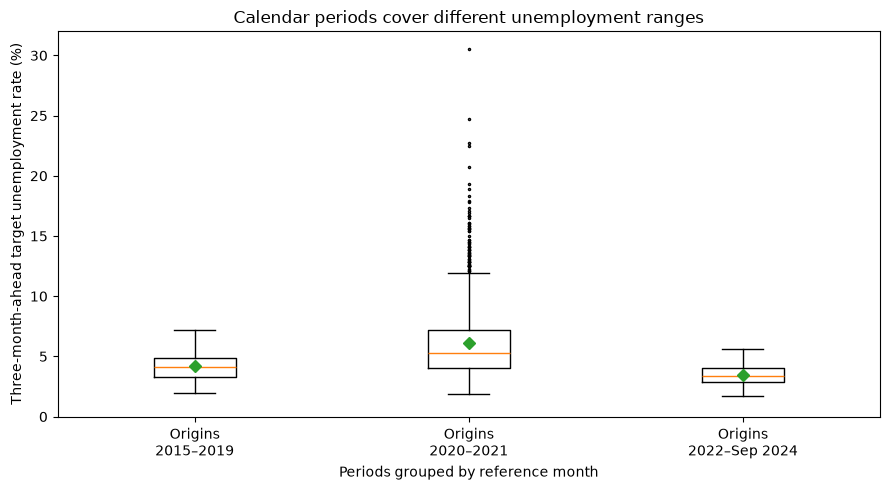

         2015–2019    2020–2021  2022–Sep 2024
count  3060.000000  1224.000000    1683.000000
mean      4.161928     6.086765       3.458348
std       1.065804     3.204191       0.792095
min       2.000000     1.900000       1.700000
25%       3.300000     4.000000       2.900000
50%       4.100000     5.300000       3.400000
75%       4.900000     7.200000       4.000000
max       7.200000    30.500000       5.600000


In [6]:
before_2020 = table.loc[table["month"] < "2020-01", "target_unemployment_rate"]
during_2020_2021 = table.loc[table["month"].between("2020-01", "2021-12"), "target_unemployment_rate"]
from_2022 = table.loc[table["month"] >= "2022-01", "target_unemployment_rate"]

plt.figure(figsize=(9, 5))
plt.boxplot([before_2020, during_2020_2021, from_2022],
            tick_labels=["Origins\n2015–2019", "Origins\n2020–2021",
                         "Origins\n2022–Sep 2024"],
            showmeans=True, meanprops={"marker": "D"},
            flierprops={"marker": ".", "markersize": 3})
plt.title("Calendar periods cover different unemployment ranges")
plt.xlabel("Periods grouped by reference month")
plt.ylabel("Three-month-ahead target unemployment rate (%)")
plt.ylim(0, 32)
plt.tight_layout()
plt.show()

print(pd.DataFrame({
    "2015–2019": before_2020.describe(),
    "2020–2021": during_2020_2021.describe(),
    "2022–Sep 2024": from_2022.describe()
}))

### Autocorrelation (Lecture 10)

- Compute each area's autocorrelation separately.
- Cover 50 states and DC, January 2015–December 2024: 120 months per area.
- Gray lines show individual areas; blue shows the median at each monthly lag.
- Use the same mean-centered ACF definition as pandas' autocorrelation plot.
- This explores temporal dependence; it does not prove forecast accuracy or select optimal lags.

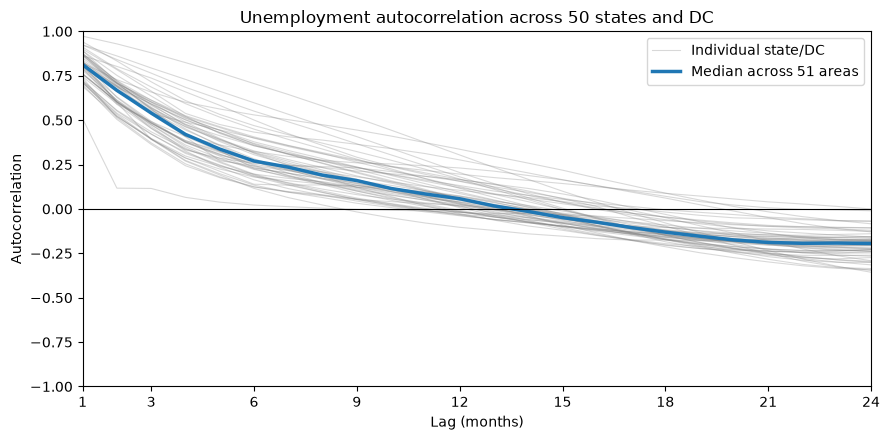

Areas: 51 | months per area: [120]
Reference months: 2015-01 to 2024-12
Median autocorrelation: {1: 0.8126055337164416, 3: 0.5400489930437681, 6: 0.26980164237354415, 12: 0.05730696497659873}
Pairs with three-month change at most 0.5 percentage points: 85.95609183844478


In [7]:
lags = np.arange(1, 25)
state_acf = {}

for state, group in data[data.month >= "2015-01"].groupby("state_code"):
    rates = group.sort_values("month")["unemployment_rate"].to_numpy()
    centered = rates - rates.mean()
    # Same mean-centered ACF definition as pandas' autocorrelation_plot.
    state_acf[state] = [
        np.sum(centered[lag:] * centered[:-lag]) / np.sum(centered ** 2)
        for lag in lags
    ]

acf_table = pd.DataFrame(state_acf, index=lags)
median_acf = acf_table.median(axis=1)

plt.figure(figsize=(9, 4.5))
state_lines = plt.plot(lags, acf_table, color="gray", alpha=0.3, linewidth=0.8)
state_lines[0].set_label("Individual state/DC")
plt.plot(lags, median_acf, color="tab:blue", linewidth=2.5,
         label="Median across 51 areas")
plt.axhline(0, color="black", linewidth=0.8)
plt.xlim(1, 24)
plt.xticks([1, 3, 6, 9, 12, 15, 18, 21, 24])
plt.ylim(-1, 1)
plt.xlabel("Lag (months)")
plt.ylabel("Autocorrelation")
plt.title("Unemployment autocorrelation across 50 states and DC")
plt.legend()
plt.tight_layout()
plt.show()

print("Areas:", acf_table.shape[1], "| months per area:",
      data[data.month >= "2015-01"].groupby("state_code").size().unique().tolist())
print("Reference months:", "2015-01", "to", data.month.max())
print("Median autocorrelation:", median_acf.loc[[1, 3, 6, 12]].to_dict())
print("Pairs with three-month change at most 0.5 percentage points:",
      100 * ((table.target_unemployment_rate - table.unemployment_rate).abs() <= 0.5).mean())


## Limitations

- Historical BLS values are revised; original release versions were not reconstructed.
- Month `t` is usually published in the following month; the target is reference month `t+3`.
- The full 2015–2024 period has already been explored; it is not an untouched test set.
- EDA does not establish predictive performance.
- Sources: [BLS methods and revisions](https://www.bls.gov/news.release/laus.tn.htm), [seasonal adjustment](https://www.bls.gov/lau/lauseas.htm).
- Data: BLS LAUS. Code prepared with Codex assistance.